In [1]:
! pip install torchvision
! pip install torchdata
! pip install torchmetrics

In [2]:
! pip install requests
! pip install pathlib


In [3]:
import torch
from torch import nn
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
import pandas as pd
import torchvision
from torchvision import datasets
from torchvision import transforms
from torchvision.transforms import ToTensor


In [4]:
device = 'cuda' if torch.cuda.is_available else 'cpu'
device

'cuda'

## Getting A Dataset

In [5]:
train_data = datasets.FashionMNIST(
    root='data',
    train=True,
    download=True,
    transform=ToTensor(),
    target_transform=None
)

In [6]:
test_data = datasets.FashionMNIST(
    root='data',
    train=False,
    download=True,
    transform=ToTensor(),
    target_transform=None
)

In [7]:
print(f'train data lenth:{len(train_data)}')
print(f'test data length:{len(test_data)}')

train data lenth:60000
test data length:10000


In [8]:
class_names = train_data.classes
class_names[9]

'Ankle boot'

In [9]:
class_to_idx = train_data.class_to_idx
class_to_idx

{'T-shirt/top': 0,
 'Trouser': 1,
 'Pullover': 2,
 'Dress': 3,
 'Coat': 4,
 'Sandal': 5,
 'Shirt': 6,
 'Sneaker': 7,
 'Bag': 8,
 'Ankle boot': 9}

In [10]:
img,label = train_data[0]
print(img.size())
print(label)


torch.Size([1, 28, 28])
9


(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

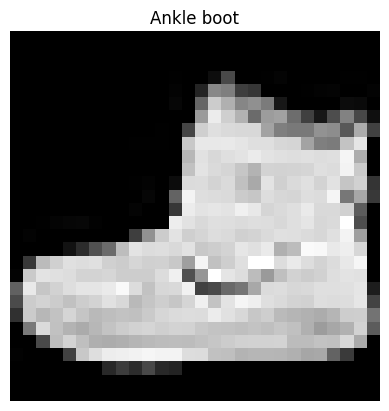

In [11]:
plt.imshow(img.squeeze(),cmap='gray')
plt.title(class_names[label])
plt.axis('off')

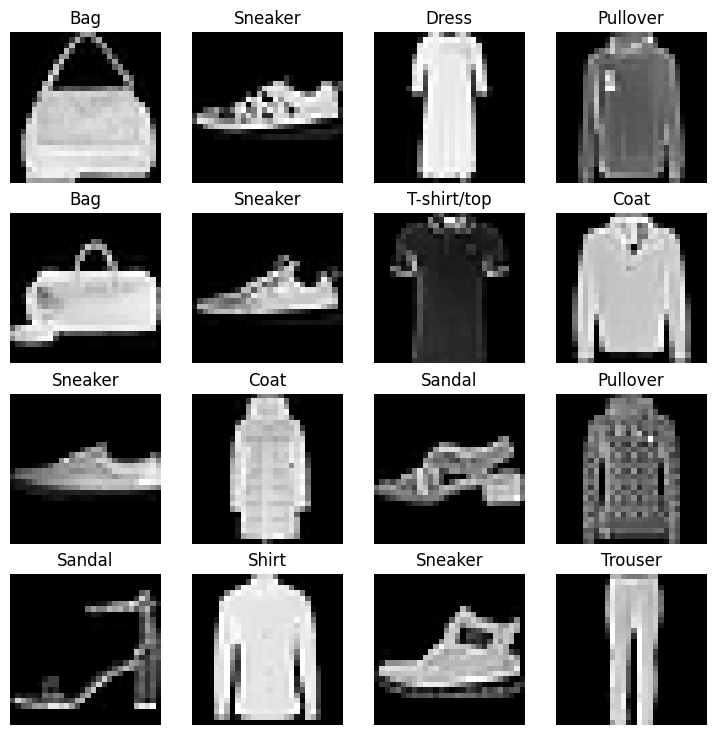

In [12]:
#torch.manual_seed(42)
fig=plt.figure(figsize=(9, 9))
r, c = 4, 4
for i in range(1, r*c + 1):
  random_idx = torch.randint(0, len(train_data), size=(1,)).item()
  img, label = train_data[random_idx]
  fig.add_subplot(r, c, i)
  plt.imshow(img.squeeze(), cmap='gray')
  plt.title(class_names[label])
  plt.axis('off')

## data loders

In [13]:
from torch.utils.data import DataLoader
train_dataloader = DataLoader(train_data,batch_size=32,shuffle=True)
test_dataloader = DataLoader(test_data,batch_size=32,shuffle=False)

# model bseline

In [14]:
from timeit import default_timer as Timer
def print_train_time(start:float, end:float,device: torch.device = None):
    ''' prints diff between start and end time.'''
    total_time = end - start
    print(f'Train time on {device} is : {total_time:.3f} seconds')
    return total_time

In [15]:
class FashionMNISTModel(nn.Module):
  def __init__(self):
    super().__init__()
    self.layer_stack = nn.Sequential(
        # output shape : ((n+2p-f)/s)+1 * ((n+2p-f)/s)+1 *hidden shape or n of filters
        nn.Conv2d(in_channels=1, out_channels=10, kernel_size=3, stride=1, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),
        nn.Conv2d(in_channels=10, out_channels=10, kernel_size=3, stride=1, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),
        nn.Flatten(),
        nn.Linear(in_features=7*7*10, out_features=len(class_names)), # Feature dimension calculation: 28 -> MaxPool -> 14 -> MaxPool -> 7 (7*7*10 = 490)
      )
  def forward(self, x):
    return self.layer_stack(x)

In [16]:
def train_step(model:torch.nn.Module,data_loader:torch.utils.data.DataLoader,loss_fn:torch.nn.Module,optimizer:torch.optim.Optimizer,accuracy_fn,device:torch.device=device):
  model.train()
  train_loss,train_acc = 0,0
  for batch,(X,y) in enumerate(data_loader):
     X, y = X.to(device), y.to(device)
     y_preds = model(X)

     loss = loss_fn(y_preds,y)
     train_loss += loss.item()
     train_acc += accuracy_fn(y_preds.argmax(dim=1),y).item()
     optimizer.zero_grad()
     loss.backward()
     optimizer.step()

  train_loss /= len(data_loader)
  train_acc /= len(data_loader)
  return {'train_loss':train_loss,'train_acc':train_acc}

In [17]:
def test_step(model:torch.nn.Module,data_loader:torch.utils.data.DataLoader,loss_fn:torch.nn.Module,accuracy_fn,device:torch.device=device):
  test_loss, test_acc = 0, 0
  model.eval()
  with torch.inference_mode():
    for X,y in data_loader:
      X, y = X.to(device), y.to(device)
      y_preds = model(X)
      test_loss += loss_fn(y_preds,y).item() # Use .item() to extract Python scalar float
      test_acc += accuracy_fn(torch.softmax(y_preds,dim=1).argmax(dim=1),y).item() # Use .item() to extract Python scalar float
  test_loss /= len(data_loader)
  test_acc /= len(data_loader)
  return{'test_loss':test_loss,'test_acc':test_acc}

In [18]:
from torchmetrics.classification.precision_recall import Precision
from torchmetrics import Accuracy


In [19]:
model = FashionMNISTModel().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(),lr=0.001)
accuracy_fn = Accuracy(task='multiclass',num_classes=len(class_names)).to(device)

In [20]:
# Training/test Loop
from tqdm.auto import tqdm
torch.manual_seed(42)

epochs = 50
start_time = Timer()
for epoch in tqdm(range(epochs)):
  print(f'epoch:{epoch}\n ------------')
  # Added optimizer argument
  print(train_step(model=model, data_loader=train_dataloader, loss_fn=loss_fn, optimizer=optimizer, accuracy_fn=accuracy_fn))
  print(test_step(model=model, data_loader=test_dataloader, loss_fn=loss_fn, accuracy_fn=accuracy_fn))

end_time = Timer()
print_train_time(start_time, end_time, device)

  0%|          | 0/50 [00:00<?, ?it/s]

epoch:0
 ------------
{'train_loss': 0.5459346576770147, 'train_acc': 0.8036833333333333}
{'test_loss': 0.4124215556124148, 'test_acc': 0.8534345047923323}
epoch:1
 ------------
{'train_loss': 0.38265197714567184, 'train_acc': 0.8624333333333334}
{'test_loss': 0.37848830546814793, 'test_acc': 0.862120607028754}
epoch:2
 ------------
{'train_loss': 0.3472836059888204, 'train_acc': 0.8770666666666667}
{'test_loss': 0.36651377265636154, 'test_acc': 0.8687100638977636}
epoch:3
 ------------
{'train_loss': 0.32363212648232775, 'train_acc': 0.8847666666666667}
{'test_loss': 0.3365453111406523, 'test_acc': 0.8828873801916933}
epoch:4
 ------------
{'train_loss': 0.3080207582056522, 'train_acc': 0.8903}
{'test_loss': 0.32914253093373663, 'test_acc': 0.8850838658146964}
epoch:5
 ------------
{'train_loss': 0.29386956448952356, 'train_acc': 0.89505}
{'test_loss': 0.3145344562281054, 'test_acc': 0.889776357827476}
epoch:6
 ------------
{'train_loss': 0.2845801313340664, 'train_acc': 0.89766666666

659.002765538

In [21]:
torch.manual_seed(42)
def eval_model(model:torch.nn.Module,
               data_loader:torch.utils.data.dataloader,
               loss_fn:torch.nn.Module,
               accuracy_fn):

  ''' Returns a dict containing the result of model predicting on data_loader'''
  loss, acc = 0, 0
  model.eval()
  with torch.inference_mode():
    for X, y in tqdm(data_loader):
      X, y = X.to(device), y.to(device)
      y_pred = model(X)

      loss += loss_fn(y_pred, y).item()
      acc += accuracy_fn(torch.softmax(y_pred, dim=1).argmax(dim=1), y).item()
  loss /= len(data_loader)
  acc /= len(data_loader)
  return {'model_name': model.__class__.__name__,
          'model_loss': loss,
          'model_acc': acc}

In [23]:
model_results = eval_model(model,test_dataloader,loss_fn,accuracy_fn)
model_results

  0%|          | 0/313 [00:00<?, ?it/s]

{'model_name': 'FashionMNISTModel',
 'model_loss': 0.31327656799623854,
 'model_acc': 0.8986621405750799}